In [22]:
import pandas as pd
from sklearn.datasets import fetch_california_housing

dados = fetch_california_housing(as_frame=True)
df = dados.frame

print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_treino = scaler.fit_transform(X_treino)
X_teste = scaler.transform(X_teste)

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

baseline = LinearRegression().fit(X_treino, y_treino)
previsoes = baseline.predict(X_teste)

print("Erro médio (MAE):", mean_absolute_error(y_teste, previsoes))

Erro médio (MAE): 0.5332001304956565


In [25]:
from tensorflow import keras
from tensorflow.keras import layers

modelo = keras.Sequential([
    layers.Input(shape=(X_treino.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

modelo.compile(optimizer="adam", loss="mse", metrics=["mae"])
modelo.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

modelo = keras.Sequential([
    layers.Input(shape=(X_treino.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])
modelo.compile(optimizer="adam", loss="mse", metrics=["mae"])

parada = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

historico = modelo.fit(
    X_treino, y_treino,
    validation_split=0.2,
    epochs=500,
    batch_size=32,
    callbacks=[parada],
    verbose=1
)

loss, mae = modelo.evaluate(X_teste, y_teste, verbose=0)
print("MAE com EarlyStopping:", mae)
print("Parou na época:", len(historico.history["loss"]))

Epoch 1/500
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.8137 - mae: 0.6225 - val_loss: 0.4528 - val_mae: 0.4703
Epoch 2/500
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3957 - mae: 0.4458 - val_loss: 0.4086 - val_mae: 0.4553
Epoch 3/500
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3688 - mae: 0.4297 - val_loss: 0.4065 - val_mae: 0.4579
Epoch 4/500
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3584 - mae: 0.4227 - val_loss: 0.3763 - val_mae: 0.4241
Epoch 5/500
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3446 - mae: 0.4142 - val_loss: 0.3607 - val_mae: 0.4156
Epoch 6/500
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3322 - mae: 0.4056 - val_loss: 0.3599 - val_mae: 0.4123
Epoch 7/500
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3233 - mae: 0.4003 - val_loss: 0.3465 - val_mae: 0.4136
Epoch 8/500
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3218 - mae: 0.3965 - val_loss: 0.3355 - val_mae: 0.3975
Epoch 9/500
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/

MAE da rede neural: 0.35444340109825134


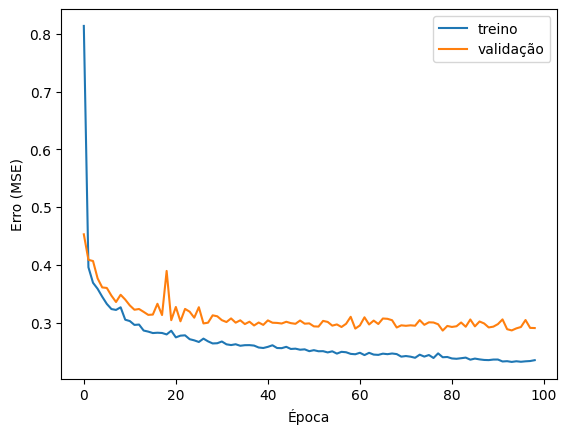

In [27]:
loss, mae = modelo.evaluate(X_teste, y_teste, verbose=0)
print("MAE da rede neural:", mae)

import matplotlib.pyplot as plt

plt.plot(historico.history["loss"], label="treino")
plt.plot(historico.history["val_loss"], label="validação")
plt.xlabel("Época")
plt.ylabel("Erro (MSE)")
plt.legend()
plt.show()

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Regressão linear: MAE=0.533 | RMSE=0.746 | R²=0.576
Rede neural: MAE=0.354 | RMSE=0.526 | R²=0.789


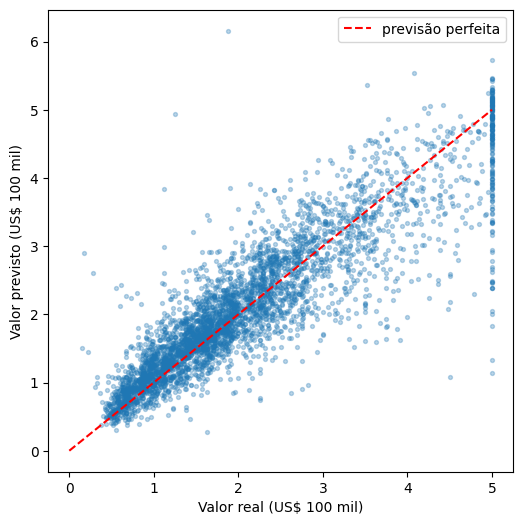

In [28]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

prev_baseline = baseline.predict(X_teste)
prev_rede = modelo.predict(X_teste).flatten()

def resumo(nome, y_real, y_prev):
    mae = mean_absolute_error(y_real, y_prev)
    rmse = np.sqrt(mean_squared_error(y_real, y_prev))
    r2 = r2_score(y_real, y_prev)
    print(f"{nome}: MAE={mae:.3f} | RMSE={rmse:.3f} | R²={r2:.3f}")

resumo("Regressão linear", y_teste, prev_baseline)
resumo("Rede neural", y_teste, prev_rede)

plt.figure(figsize=(6, 6))
plt.scatter(y_teste, prev_rede, alpha=0.3, s=8)
plt.plot([0, 5], [0, 5], color="red", linestyle="--", label="previsão perfeita")
plt.xlabel("Valor real (US$ 100 mil)")
plt.ylabel("Valor previsto (US$ 100 mil)")
plt.legend()
plt.show()